In [2]:
import os
os.environ.pop("PYTHONPATH", None)

import sys
sys.path = [
    p for p in sys.path
    if "/opt/software-current/" not in p
]

import regex
print("regex:", regex.__file__)

regex: /mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/regex/__init__.py


In [3]:
import pandas as pd

df = pd.read_csv("images.csv").fillna("")

In [4]:
import torch
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torch.nn.functional as F

MODEL_NAME = "google/siglip2-base-patch16-224"

device = "cuda" if torch.cuda.is_available() else "cpu"

model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
processor = AutoProcessor.from_pretrained(MODEL_NAME)


def embed(image_path: str):
    image = Image.open(image_path).convert("RGB")
    inputs = processor(images=image, return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_image_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

def embed_text(text: str):
    inputs = processor(text=[text],
        padding="max_length", return_tensors="pt").to(device)

    with torch.inference_mode():
        output = model.get_text_features(**inputs)
        embedding = output.pooler_output
        embedding = F.normalize(embedding, p=2, dim=-1)

    return embedding.squeeze(0)

/mnt/home/linpaul1/Documents/SPROUT/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 408/408 [00:00<00:00, 10816.96it/s]


In [5]:
image_embeddings = torch.stack([
    embed(str(row["image_path"])).squeeze(0).cpu()
    for _, row in df.iterrows()
]).to(device)

caption_embeddings = torch.stack([
    embed_text(str(caption)).cpu()
    for caption in df["caption"]
]).to(device)

query = "laptop twee"

query_embedding = embed_text(query).to(device)

image_scores = image_embeddings @ query_embedding
caption_scores = caption_embeddings @ query_embedding

combined_scores = (
    0.7 * image_scores
    + (1 - 0.3) * caption_scores
)

df[f"score_combined_{query}"] = combined_scores.cpu().numpy()

# Evaluation

In [9]:
ranked = df.sort_values(f"score_combined_{query}", ascending=False)
relevant = ranked["label"].astype(bool).to_numpy()

n_relevant = relevant.sum()
top_k = relevant[:10]

precision_k = top_k.sum() / len(top_k) if len(top_k) else 0
recall_k = top_k.sum() / n_relevant if n_relevant else 0

precisions = [
    relevant[:i + 1].sum() / (i + 1)
    for i in range(len(relevant))
    if relevant[i]
]

ap = sum(precisions) / n_relevant if n_relevant else 0

print({
    "query": f"score_combined_{query}".replace("score_combined_", ""),
    f"precision@{10}": precision_k,
    f"recall@{10}": recall_k,
    "average_precision": ap,
})

{'query': 'laptop twee', 'precision@10': np.float64(0.1), 'recall@10': np.float64(0.1), 'average_precision': np.float64(0.24725220495243377)}


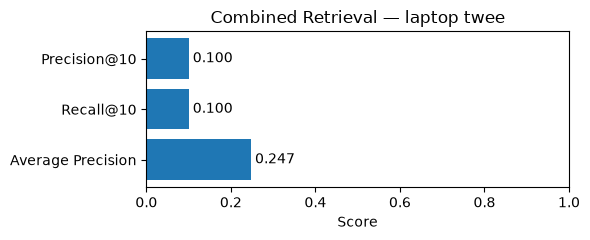

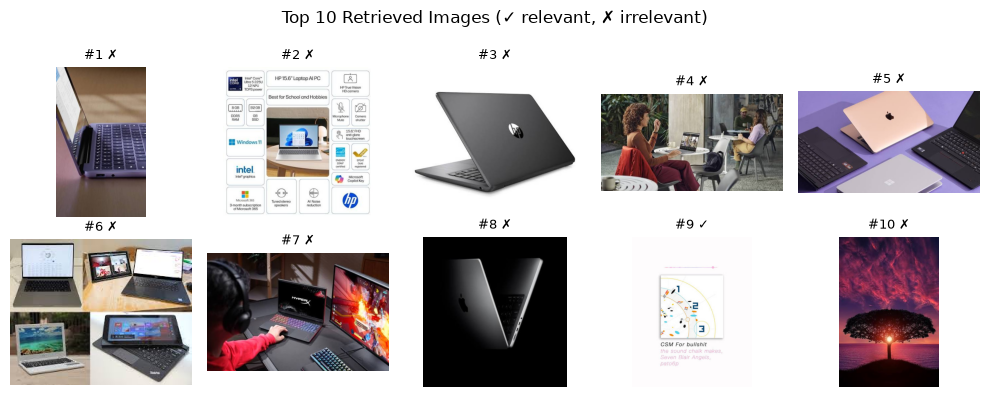

In [ ]:

from IPython.display import display

score_col = f"score_combined_{query}"
ranked = df.sort_values(score_col, ascending=False).reset_index(drop=True)
relevant = ranked["label"].astype(bool).to_numpy()

k = min(10, len(ranked))
top_k = relevant[:k]
n_relevant = relevant.sum()

precision_k = top_k.sum() / k if k else 0
recall_k = top_k.sum() / n_relevant if n_relevant else 0

precisions = [
    relevant[:i + 1].sum() / (i + 1)
    for i in range(len(relevant))
    if relevant[i]
]
ap = sum(precisions) / n_relevant if n_relevant else 0

# Chart 1: Retrieval statistics
metrics = {
    f"Precision@{k}": precision_k,
    f"Recall@{k}": recall_k,
    "Average Precision": ap,
}

fig, ax = plt.subplots(figsize=(6, 2.5))
bars = ax.barh(list(metrics.keys()), list(metrics.values()))
ax.set_xlim(0, 1)
ax.set_xlabel("Score")
ax.set_title(f"Combined Retrieval — {query}")
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Chart 2: Small grid of top 10 retrieved images
# Change 'image_path' to your actual image column.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.axis("off")

    if i >= k:
        continue

    row = ranked.iloc[i]
    img = Image.open(row["image_path"])
    ax.imshow(img)
    ax.set_title(
        f"#{i+1} {'✓' if bool(row['label']) else '✗'}",
        fontsize=9
    )

plt.suptitle("Top 10 Retrieved Images (✓ relevant, ✗ irrelevant)")
plt.tight_layout()
plt.show()